# Crossing Boundaries, Flipping Reasons: Reproducible Analysis Notebook

**Authors:** Shahoud Shahid (23i-2515), Saif Shahzad (23i-2634)  
**Course:** Methods in Business Research — Assignment 3

This notebook mirrors every section of the paper, invoking modules under `src/` and loading cached experimental outputs produced by `scripts/01_clean.py` through `scripts/05_plots.py`.


In [1]:
import json
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import Image, display

ANALYSIS_ROOT = Path("..").resolve()
if str(ANALYSIS_ROOT) not in sys.path:
    sys.path.insert(0, str(ANALYSIS_ROOT))

from src.data import load_config, resolve_path
from src.stats import power_analysis_correlation

cfg = load_config(ANALYSIS_ROOT / "config.yaml")
results_dir = resolve_path(cfg["paths"]["results_dir"])
figures_dir = resolve_path(cfg["paths"]["figures_dir"])
print("Results dir:", results_dir)
print("Figures dir:", figures_dir)


Results dir: C:\Users\shaho\OneDrive - FAST National University\Attachments\@Fast\Semester 7\Methods in Business Research\Project\Assignment 3\analysis\results
Figures dir: C:\Users\shaho\OneDrive - FAST National University\Attachments\@Fast\Semester 7\Methods in Business Research\Project\Assignment 3\analysis\results\figures


## 1. Data Screening & Exact Power Analysis (`Stage 01`)


In [2]:
sample_profile = pd.read_csv(results_dir / "sample_profile.csv")
data_screening = pd.read_csv(results_dir / "data_screening.csv")
with open(results_dir / "power_analysis.json", "r", encoding="utf-8") as fh:
    power_info = json.load(fh)

display(sample_profile)
print("Live exact power calculation:", power_analysis_correlation(rho=0.20, alpha=0.05, power_target=0.80))
print("Cached Stage 01 power_analysis.json:", power_info)
print("Top skewed / outlier-heavy features across datasets:")
display(data_screening.sort_values("outlier_pct", ascending=False).head(12))


,dataset,role,n_rows,n_features,n_perturbable_features,n_defaults,default_rate_pct,total_missing_cells,missing_pct_overall,part1_train_pool_n,part1_test_n,part2_train_n,part2_test_n,exposure_col,exposure_median,exposure_iqr
0,hmeq,Base-paper benchmark 1 (cost + adverse-action ...,5960,12,6,1189,19.95,5271,7.37,5660,300,4172,1788,LOAN,16300.0,12200.00
1,sgcs,Base-paper benchmark 2 (small credit sample),1000,20,3,300,30.00,0,0.00,700,300,700,300,amount,2319.5,2606.75
2,taiwan,Independent main credit sample,30000,23,13,6636,22.12,0,0.00,29700,300,21000,9000,LIMIT_BAL,140000.0,190000.00


Live exact power calculation: {'rho': 0.2, 'alpha': 0.05, 'power_target': 0.8, 'two_sided': True, 'n_exact': 193, 'achieved_power_exact': 0.8000845550829667, 'n_fisher_z': 194, 'n_fisher_z_continuous': 193.9680401839892}
Cached Stage 01 power_analysis.json: {'rho': 0.2, 'alpha': 0.05, 'power_target': 0.8, 'two_sided': True, 'n_exact': 193, 'achieved_power_exact': 0.8000845550829667, 'n_fisher_z': 194, 'n_fisher_z_continuous': 193.9680401839892}
Top skewed / outlier-heavy features across datasets:


,dataset,variable,type,perturbable,n_valid,missing_count,missing_pct,mean,sd,median,iqr,outlier_count,outlier_pct,skewness,n_unique,mode
7,hmeq,DELINQ,count,False,5380,580,9.732,0.4494,1.1273,0.0,0.00,1201,22.323,4.0231,14,NaN
38,taiwan,PAY_2,ordinal,False,30000,0,0.000,-0.1338,1.1972,0.0,1.00,4410,14.700,0.7906,11,NaN
39,taiwan,PAY_3,ordinal,False,30000,0,0.000,-0.1662,1.1969,0.0,1.00,4209,14.030,0.8407,11,NaN
6,hmeq,DEROG,count,False,5252,708,11.879,0.2546,0.8460,0.0,0.00,725,13.804,5.3209,11,NaN
40,taiwan,PAY_4,ordinal,False,30000,0,0.000,-0.2207,1.1691,0.0,1.00,3508,11.693,0.9996,11,NaN
37,taiwan,PAY_0,ordinal,False,30000,0,0.000,-0.0167,1.1238,0.0,1.00,3130,10.433,0.7320,11,NaN
42,taiwan,PAY_6,ordinal,False,30000,0,0.000,-0.2911,1.1500,0.0,1.00,3079,10.263,0.9480,10,NaN
52,taiwan,PAY_AMT4,continuous,True,30000,0,0.000,4826.0769,15666.1597,1500.0,3717.25,2994,9.980,12.9050,6937,NaN
41,taiwan,PAY_5,ordinal,False,30000,0,0.000,-0.2662,1.1332,0.0,1.00,2968,9.893,1.0082,10,NaN
54,taiwan,PAY_AMT6,continuous,True,30000,0,0.000,5215.5026,17777.4658,1500.0,3882.25,2958,9.860,10.6407,6939,NaN


## 2. Part 1: Base-Paper Replication & E1 Variance Decomposition (`Stage 02`)


In [3]:
p1_trend = pd.read_csv(results_dir / "part1_h1a_trend.csv")
p1_idcs = pd.read_csv(results_dir / "part1_h1b_idcs_vs_trad.csv")
p1_e1 = pd.read_csv(results_dir / "part1_e1_variance_decomp.csv")

print("H1a (Jonckheere-Terpstra & Spearman across imbalance pi):")
display(p1_trend)
print("H1b (IDCS vs Traditional CoV/SRA):")
display(p1_idcs)
print("E1 (Refit vs Explainer Stochasticity Variance Share):")
display(p1_e1)


H1a (Jonckheere-Terpstra & Spearman across imbalance pi):


,dataset,model,explainer,metric,jt_z,jt_tau,jt_pvalue,spearman_rho,spearman_ci_low,spearman_ci_high,spearman_pvalue,median_min_pi,median_max_pi,median_ratio_min_over_max,jt_p_holm,supported_holm
0,hmeq,boost,lime,cov,-40.872594,-0.862029,0.000000e+00,-0.902339,-0.912916,-0.890550,0.000000e+00,1.063668,0.604001,1.761035,0.000000e+00,True
1,hmeq,boost,lime,sra,-39.564696,-0.834444,0.000000e+00,-0.883393,-0.895839,-0.869562,0.000000e+00,20.134028,9.705556,2.074485,0.000000e+00,True
2,hmeq,boost,permutation_shap,cov,-42.020339,-0.886236,0.000000e+00,-0.915946,-0.925146,-0.905671,0.000000e+00,1.774362,0.752928,2.356618,0.000000e+00,True
3,hmeq,boost,permutation_shap,sra,-30.385211,-0.640843,4.307156e-203,-0.727928,-0.753619,-0.700016,8.652121e-248,10.025893,5.393287,1.858958,2.153578e-202,True
4,hmeq,csboost,lime,cov,-37.094087,-0.782338,1.749560e-301,-0.844716,-0.860798,-0.826949,0.000000e+00,0.994979,0.613086,1.622903,1.049736e-300,True
5,hmeq,csboost,lime,sra,-38.436392,-0.810648,0.000000e+00,-0.865689,-0.879829,-0.850019,0.000000e+00,20.089583,9.590972,2.094635,0.000000e+00,True
6,hmeq,csboost,permutation_shap,cov,-40.831712,-0.861167,0.000000e+00,-0.893341,-0.904813,-0.880573,0.000000e+00,1.906825,0.800572,2.381828,0.000000e+00,True
7,hmeq,csboost,permutation_shap,sra,-32.027435,-0.675479,2.263335e-225,-0.762091,-0.785177,-0.736891,4.348867e-285,10.911111,6.013241,1.814514,2.037001e-224,True
8,hmeq,cslogit,lime,cov,-36.293310,-0.765449,1.031496e-288,-0.833333,-0.850441,-0.814464,0.000000e+00,1.041916,0.575479,1.810518,5.157482e-288,True
9,hmeq,cslogit,lime,sra,-34.895641,-0.735971,4.328427e-267,-0.806627,-0.826064,-0.785273,0.000000e+00,19.252083,8.944769,2.152329,5.194112e-266,True


H1b (IDCS vs Traditional CoV/SRA):


,dataset,pi,pi_pct,pair,explainer,metric,median_idcs,median_trad,wilcoxon_p,rank_biserial_r,ks_stat,ks_p,wilcoxon_p_holm,supported_holm
0,hmeq,0.01,1.0,cslogit_vs_logit,lime,cov,1.041916,0.702081,3.262922e-51,0.999690,0.960000,6.022081e-155,1.216712e-49,True
1,hmeq,0.01,1.0,cslogit_vs_logit,lime,sra,19.252083,11.027778,3.041742e-51,1.000000,0.996667,8.881787e-177,1.216666e-49,True
2,hmeq,0.01,1.0,csboost_vs_boost,lime,cov,0.994979,1.063668,1.000000e+00,-0.464939,0.316667,1.074750e-13,1.000000e+00,False
3,hmeq,0.01,1.0,csboost_vs_boost,lime,sra,20.089583,20.134028,6.853787e-01,-0.032159,0.076667,3.416595e-01,1.000000e+00,False
4,hmeq,0.01,1.0,cslogit_vs_logit,permutation_shap,cov,2.277073,0.959817,3.041780e-51,1.000000,1.000000,1.480298e-179,1.216712e-49,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,sgcs,0.30,30.0,csboost_vs_boost,lime,sra,57.435770,16.298917,3.041780e-51,1.000000,0.930000,4.460844e-141,1.216666e-49,True
76,sgcs,0.30,30.0,cslogit_vs_logit,permutation_shap,cov,1.452191,0.565865,3.041780e-51,1.000000,1.000000,1.480298e-179,1.216712e-49,True
77,sgcs,0.30,30.0,cslogit_vs_logit,permutation_shap,sra,78.806709,9.012153,3.041780e-51,1.000000,1.000000,1.480298e-179,1.216666e-49,True
78,sgcs,0.30,30.0,csboost_vs_boost,permutation_shap,cov,0.379030,0.275799,3.041780e-51,1.000000,1.000000,1.480298e-179,1.216712e-49,True


E1 (Refit vs Explainer Stochasticity Variance Share):


,dataset,pi,pi_pct,model,explainer,pooled_explainer_share,pooled_explainer_share_ci_low,pooled_explainer_share_ci_high,pooled_icc,mean_instance_explainer_share,...,median_instance_explainer_share,sigma2_explainer_total,sigma2_refit_total,n_instances,n_valid_instances,J_refits,K_repeats,P_features,n_boot,seed
0,sgcs,0.01,1.0,logit,permutation_shap,0.343249,0.331684,0.355617,0.656751,0.425686,...,0.399971,3.277060,6.270119,300,300,10,5,45,5000,42
1,sgcs,0.01,1.0,logit,lime,0.413800,0.410884,0.416792,0.586200,0.413959,...,0.414913,11.687188,16.556381,300,300,10,5,45,5000,42
2,sgcs,0.01,1.0,boost,permutation_shap,0.066906,0.057991,0.077098,0.933094,0.099911,...,0.091993,0.030927,0.431312,300,300,10,5,45,5000,42
3,sgcs,0.01,1.0,boost,lime,0.360166,0.355771,0.364661,0.639834,0.359475,...,0.359024,0.974198,1.730663,300,300,10,5,45,5000,42
4,sgcs,0.30,30.0,logit,permutation_shap,0.264192,0.240176,0.288586,0.735808,0.228336,...,0.190672,0.479478,1.335404,300,300,10,5,45,5000,42
5,sgcs,0.30,30.0,logit,lime,0.957733,0.955967,0.959527,0.042267,0.957693,...,0.958456,7.590962,0.335006,300,300,10,5,45,5000,42
6,sgcs,0.30,30.0,boost,permutation_shap,0.040518,0.031080,0.051162,0.959482,0.034450,...,0.017769,0.018909,0.447762,300,300,10,5,45,5000,42
7,sgcs,0.30,30.0,boost,lime,0.961990,0.960383,0.963594,0.038010,0.962071,...,0.964802,3.040031,0.120119,300,300,10,5,45,5000,42


## 3. Part 2: Main Extension Results — H2 through H6 & Measurement Quality (`Stage 03`)


In [4]:
p2_perf = pd.read_csv(results_dir / "part2_model_performance.csv")
h2_df = pd.read_csv(results_dir / "part2_h2_noise_floor.csv")
h3_df = pd.read_csv(results_dir / "part2_h3_abs_dp_auroc.csv")
h4a_df = pd.read_csv(results_dir / "part2_h4a_mediation.csv")
h4b_df = pd.read_csv(results_dir / "part2_h4b_double_dissociation.csv")
h4c_df = pd.read_csv(results_dir / "part2_h4c_discretisation.csv")
h5_df = pd.read_csv(results_dir / "part2_h5_fragility_auroc.csv")
mq_df = pd.read_csv(results_dir / "part2_measurement_quality.csv")
with open(results_dir / "part2_h6_exploratory.json", "r", encoding="utf-8") as fh:
    h6_res = json.load(fh)

print("Predictive Performance (Part 2 Holdout):")
display(p2_perf[["dataset", "model", "auc", "ap", "brier", "rel_aec", "savings_at_prior"]])
print("H2 (Instability Beyond Stochastic Noise Floor):")
display(h2_df[h2_df["s"] == 0.05])
print("H3 (|Delta p| AUROC Insufficiency):")
display(h3_df[h3_df["subset"] == "full"])


Predictive Performance (Part 2 Holdout):


,dataset,model,auc,ap,brier,rel_aec,savings_at_prior
0,taiwan,lr,0.716246,0.498244,0.146079,0.082599,0.183743
1,taiwan,rf,0.774646,0.551193,0.135934,0.158042,0.346694
2,taiwan,xgb,0.776611,0.547762,0.136316,0.162770,0.331495
3,taiwan,cslogit,0.669687,0.463949,0.204708,0.322366,0.322616
4,taiwan,csboost,0.702055,0.488702,0.227208,0.399504,0.410805
5,hmeq,lr,0.781675,0.573462,0.122949,0.206712,0.258683
6,hmeq,rf,0.959735,0.875614,0.063690,0.497276,0.775287
7,hmeq,xgb,0.964370,0.903320,0.059781,0.623666,0.706607
8,hmeq,cslogit,0.693371,0.334010,0.236018,0.403203,0.315248
9,hmeq,csboost,0.930596,0.818545,0.085628,0.672127,0.703505


H2 (Instability Beyond Stochastic Noise Floor):


,dataset,model,explainer,s,type,n_instances,k_nonzero,share_gt_floor,ci_low,ci_high,pop_weighted_share,median_d_k,median_noise_floor,median_u_bar,mean_u_bar,wilcoxon_p,rank_biserial_r,supported_cell,wilcoxon_p_holm
1,hmeq,lr,LIME,0.05,stochastic,197,33,0.167513,0.118202,0.227128,0.189016,0.154667,0.400000,0.000000,0.031269,1.0,-0.909142,False,1.0
3,hmeq,lr,LinearSHAP,0.05,exact,197,61,0.309645,0.245858,0.379267,0.322081,0.000000,0.000000,0.000000,0.080393,NaN,NaN,True,NaN
5,hmeq,rf,LIME,0.05,stochastic,166,36,0.216867,0.156753,0.287374,0.219468,0.269333,0.400000,0.000000,0.070682,1.0,-0.792014,False,1.0
7,hmeq,rf,TreeSHAP,0.05,exact,166,121,0.728916,0.654572,0.794892,0.718307,0.080000,0.000000,0.200000,0.304064,NaN,NaN,True,NaN
9,hmeq,xgb,LIME,0.05,stochastic,175,61,0.348571,0.278234,0.424136,0.298556,0.342857,0.400000,0.000000,0.112461,1.0,-0.717769,False,1.0
11,hmeq,xgb,TreeSHAP,0.05,exact,175,148,0.845714,0.783517,0.895796,0.893002,0.224000,0.000000,0.520000,0.521368,NaN,NaN,True,NaN
13,sgcs,lr,LIME,0.05,stochastic,200,60,0.300000,0.237390,0.368650,0.303867,0.451810,0.666667,0.000000,0.051236,1.0,-0.965373,False,1.0
15,sgcs,lr,LinearSHAP,0.05,exact,200,4,0.020000,0.005476,0.050414,0.020000,0.000000,0.000000,0.000000,0.005400,NaN,NaN,True,NaN
17,sgcs,rf,LIME,0.05,stochastic,200,81,0.405000,0.336335,0.476525,0.404533,0.298667,0.400000,0.000000,0.066950,1.0,-0.909055,False,1.0
19,sgcs,rf,TreeSHAP,0.05,exact,200,122,0.610000,0.538679,0.678009,0.600667,0.048000,0.000000,0.120000,0.197409,NaN,NaN,True,NaN


H3 (|Delta p| AUROC Insufficiency):


,dataset,model,explainer,subset,rc_rate,auroc,se,ci_low,ci_high,n_obs,n_clusters,n_boot,n_valid_boot,seed,upper_ci_lt_070
0,hmeq,lr,LIME,full,0.0297,0.472129,0.059449,0.377607,0.607452,10000,200,5000,5000,42,True
2,hmeq,lr,LinearSHAP,full,0.0499,0.623137,0.021914,0.580467,0.666492,10000,200,5000,5000,42,True
4,hmeq,rf,LIME,full,0.0682,0.678767,0.034083,0.610023,0.745786,10000,200,5000,5000,42,False
6,hmeq,rf,TreeSHAP,full,0.3666,0.801370,0.016079,0.768993,0.832048,10000,200,5000,5000,42,False
8,hmeq,xgb,LIME,full,0.0792,0.571813,0.025541,0.520677,0.622063,10000,200,5000,5000,42,True
10,hmeq,xgb,TreeSHAP,full,0.5047,0.739767,0.016724,0.707245,0.773141,10000,200,5000,5000,42,False
12,sgcs,lr,LIME,full,0.0514,0.519134,0.026335,0.467028,0.570447,10000,200,5000,5000,42,True
14,sgcs,lr,LinearSHAP,full,0.0037,0.379510,0.200165,0.263765,0.998400,10000,200,5000,4908,42,False
16,sgcs,rf,LIME,full,0.0636,0.526974,0.022764,0.482344,0.571532,10000,200,5000,5000,42,True
18,sgcs,rf,TreeSHAP,full,0.1380,0.776946,0.020588,0.735581,0.816738,10000,200,5000,5000,42,False


In [5]:
print("H4a (Cluster-Bootstrap Mediation through C_tree / C_bin):")
display(h4a_df)
print("H4b (Double Dissociation Joint Cluster-Robust Logit):")
display(h4b_df)
print("H4c (LIME Discretisation ON vs OFF):")
display(h4c_df)
print("H5 (Ex-Ante Fragility F(x) vs Margin/Tree-Variance AUROC):")
display(h5_df)
print("H6 Exploratory Summary:", json.dumps(h6_res, indent=2)[:1500])
print("Measurement Quality (ICC, Convergent, Discriminant):")
display(mq_df)


H4a (Cluster-Bootstrap Mediation through C_tree / C_bin):


,dataset,model,explainer,mediator,a,a_se,a_ci_low,a_ci_high,b,b_se,...,total_c,total_ci_low,total_ci_high,proportion_mediated,n_obs,n_clusters,n_boot,seed,p_holm,supported_holm
0,hmeq,lr,LIME,c_bin,4.649409,0.395572,3.882310,5.424763,0.017360,0.007914,...,0.123066,-0.059264,0.314725,0.655856,9799,197,5000,42,0.1120,False
1,hmeq,rf,LIME,c_bin,4.483035,0.500367,3.507391,5.483175,0.047788,0.014669,...,0.139738,-0.122039,0.396538,1.533128,6691,184,5000,42,0.0072,True
2,hmeq,rf,TreeSHAP,c_tree,68.558150,2.266416,64.029007,72.994766,0.026431,0.003991,...,1.099553,0.813641,1.388381,1.647973,6691,184,5000,42,0.0000,True
3,hmeq,xgb,LIME,c_bin,2.435653,0.664964,1.107375,3.688420,0.045346,0.010201,...,-0.325017,-0.567939,-0.094599,-0.339819,6344,195,5000,42,0.0056,True
4,hmeq,xgb,TreeSHAP,c_tree,15.063839,0.483036,14.137592,16.008114,0.211750,0.018631,...,3.072496,2.625768,3.531661,1.038167,6344,195,5000,42,0.0000,True
5,sgcs,lr,LIME,c_bin,1.637201,0.274327,1.110168,2.190096,-0.000414,0.009572,...,-0.070457,-0.241750,0.106142,0.009626,9974,200,5000,42,1.0000,False
6,sgcs,rf,LIME,c_bin,1.550519,0.249075,1.069938,2.048627,0.114596,0.011870,...,0.051047,-0.122419,0.221083,3.480755,9852,200,5000,42,0.0000,True
7,sgcs,rf,TreeSHAP,c_tree,5.490811,0.205005,5.095895,5.886034,0.187403,0.020199,...,1.292248,1.059751,1.531790,0.796283,9852,200,5000,42,0.0000,True
8,sgcs,xgb,LIME,c_bin,1.519466,0.285708,0.941899,2.079534,0.092054,0.013687,...,-0.024922,-0.199502,0.149776,-5.612361,9008,200,5000,42,0.0000,True
9,sgcs,xgb,TreeSHAP,c_tree,0.029909,0.005417,0.019686,0.041104,7.713568,0.992622,...,0.290868,0.175466,0.413894,0.793159,9008,200,5000,42,0.0000,True


H4b (Double Dissociation Joint Cluster-Robust Logit):


,scope,dataset,explainer,predictor,converged,n_obs,n_clusters,coef,se,z,pvalue,ci_low,ci_high,odds_ratio,or_ci_low,or_ci_high,p_holm
0,pooled_trees,all,TreeSHAP,c_tree,True,48547,1178,0.086740,0.009124,9.506772,1.966704e-21,0.068857,0.104622,1.090613,1.071283,1.110291,7.866815e-21
1,pooled_trees,all,TreeSHAP,c_bin,True,48547,1178,0.171112,0.026791,6.386819,1.693722e-10,0.118601,0.223622,1.186623,1.125921,1.250598,5.081167e-10
2,per_dataset,hmeq,TreeSHAP,c_tree,True,13035,379,0.344292,0.033648,10.232218,1.422242e-24,0.278343,0.410241,1.410991,1.320940,1.507180,NaN
3,per_dataset,hmeq,TreeSHAP,c_bin,True,13035,379,0.122884,0.091302,1.345900,1.783349e-01,-0.056066,0.301834,1.130753,0.945477,1.352336,NaN
4,per_dataset,sgcs,TreeSHAP,c_tree,True,18860,400,3.379810,0.295346,11.443544,2.533222e-30,2.800941,3.958678,29.365187,16.460136,52.388034,NaN
5,per_dataset,sgcs,TreeSHAP,c_bin,True,18860,400,0.278369,0.121965,2.282368,2.246763e-02,0.039322,0.517416,1.320973,1.040105,1.677686,NaN
6,per_dataset,taiwan,TreeSHAP,c_tree,True,16652,399,0.084960,0.009498,8.945148,3.714505e-19,0.066344,0.103575,1.088673,1.068594,1.109129,NaN
7,per_dataset,taiwan,TreeSHAP,c_bin,True,16652,399,0.146754,0.027862,5.267110,1.385883e-07,0.092145,0.201364,1.158069,1.096524,1.223069,NaN
8,pooled_trees,all,LIME,c_tree,True,48547,1178,-0.018829,0.013658,-1.378530,1.680398e-01,-0.045599,0.007942,0.981348,0.955425,1.007973,1.680398e-01
9,pooled_trees,all,LIME,c_bin,True,48547,1178,0.308523,0.050506,6.108655,1.004742e-09,0.209533,0.407513,1.361413,1.233103,1.503075,2.009483e-09


H4c (LIME Discretisation ON vs OFF):


,dataset,n_instances,mean_u_on,mean_u_off,median_u_on,median_u_off,wilcoxon_p,rank_biserial_r
0,hmeq,472,0.074874,0.012396,0.0,0.0,1.086748e-13,0.694087
1,sgcs,428,0.081835,0.014688,0.0,0.0,2.621694e-16,0.693063
2,taiwan,575,0.034680,0.029543,0.0,0.0,7.161639e-02,0.119204


H5 (Ex-Ante Fragility F(x) vs Margin/Tree-Variance AUROC):


,dataset,model,explainer,baseline,is_perturbation_free,n_instances,pos_rate_y_instab,auroc_f,auroc_baseline,delta_auroc,...,delong_p,delong_ci_low,delong_ci_high,boot_p,boot_ci_low,boot_ci_high,spearman_f_ubar,spearman_f_ubar_p,delong_p_holm,supported_holm
0,hmeq,lr,LIME,B_margin,True,197,0.035533,0.496241,0.489474,0.006767,...,4.817999e-01,-0.283852,0.297386,0.478287,-0.295543,0.294800,-0.044070,5.386104e-01,1.000000e+00,False
1,hmeq,lr,LIME,B_var,True,197,0.035533,0.496241,0.222180,0.274060,...,2.156150e-02,0.008476,0.539644,0.027216,-0.005187,0.550487,-0.044070,5.386104e-01,3.881069e-01,False
2,hmeq,lr,LIME,posthoc_abs_dp,False,197,0.035533,0.496241,0.393233,0.103008,...,2.465344e-01,-0.191536,0.397551,0.238343,-0.196891,0.407292,-0.044070,5.386104e-01,NaN,False
3,hmeq,rf,LIME,B_margin,True,166,0.114458,0.706409,0.361439,0.344970,...,1.720817e-03,0.113836,0.576104,0.002800,0.105086,0.568125,0.211811,6.152654e-03,3.785797e-02,True
4,hmeq,rf,LIME,B_var,True,166,0.114458,0.706409,0.624597,0.081812,...,1.175795e-01,-0.053255,0.216879,0.111400,-0.047461,0.224828,0.211811,6.152654e-03,1.000000e+00,False
5,hmeq,rf,LIME,posthoc_abs_dp,False,166,0.114458,0.706409,0.765306,-0.058897,...,7.648016e-01,-0.218818,0.101024,0.775600,-0.216046,0.109395,0.211811,6.152654e-03,NaN,False
6,hmeq,rf,TreeSHAP,B_margin,True,166,0.518072,0.649709,0.532340,0.117369,...,4.417227e-02,-0.017615,0.252353,0.048000,-0.016302,0.252109,0.361191,1.745547e-06,7.509285e-01,False
7,hmeq,rf,TreeSHAP,B_var,True,166,0.518072,0.649709,0.621439,0.028270,...,2.692824e-01,-0.061828,0.118368,0.271600,-0.062285,0.120918,0.361191,1.745547e-06,1.000000e+00,False
8,hmeq,rf,TreeSHAP,posthoc_abs_dp,False,166,0.518072,0.649709,0.701817,-0.052108,...,8.925072e-01,-0.134471,0.030256,0.890600,-0.135532,0.030710,0.361191,1.745547e-06,NaN,False
9,hmeq,xgb,LIME,B_margin,True,175,0.188571,0.670081,0.277422,0.392659,...,5.787484e-07,0.234396,0.550922,0.000000,0.225111,0.546292,0.296007,6.971680e-05,1.446871e-05,True


H6 Exploratory Summary: {
  "nested_ols": {
    "models": [
      {
        "model": "M0: Base Factors",
        "n_obs": 3458,
        "df_model": 6,
        "df_resid": 3451,
        "r2": 0.31511221697502223,
        "adj_r2": 0.3139214529361495,
        "rmse": 0.23241965442385287,
        "aic": -271.52930366856344,
        "bic": -228.4901840048608,
        "f_stat_overall": 172.14289656684812,
        "f_pvalue_overall": 4.998915781990962e-192,
        "predictors": [
          "ds_sgcs",
          "ds_taiwan",
          "m_rf",
          "m_xgb",
          "e_LinearSHAP",
          "e_TreeSHAP"
        ],
        "coefficients": {
          "const": {
            "coef": 0.06652642997072963,
            "se_hc3": 0.008188935446857575,
            "t": 8.123941188992827,
            "pvalue": 4.512844980672335e-16,
            "ci_low": 0.05047641142316538,
            "ci_high": 0.08257644851829389
          },
          "ds_sgcs": {
            "coef": -0.1047908026029082,
   

,dataset,model,explainer,is_deterministic,mean_noise_floor_q95,icc_1_analog,rho_dk_drho,rho_dk_d1,rho_drho_d1,mean_abs_monotrait,mean_abs_heterotrait,htmt_ratio,htmt_ci_low,htmt_ci_high,discriminant_passes_085
0,hmeq,lr,LIME,False,0.383067,0.820089,0.114757,0.259384,0.574280,0.316140,0.081454,0.144869,0.094142,0.207406,True
1,hmeq,lr,LinearSHAP,True,0.000000,1.000000,0.164748,0.169918,0.498158,0.277608,0.337267,0.640115,0.597087,0.683832,True
2,hmeq,rf,LIME,False,0.423200,0.764637,0.193093,0.369425,0.650445,0.404321,0.038117,0.059945,0.032545,0.140552,True
3,hmeq,rf,TreeSHAP,True,0.000000,1.000000,0.253906,0.307083,0.720960,0.427317,0.437830,0.669777,0.612575,0.723557,True
4,hmeq,xgb,LIME,False,0.470229,0.705744,0.137335,0.349575,0.586393,0.357767,0.066755,0.111605,0.063385,0.168567,True
5,hmeq,xgb,TreeSHAP,True,0.000000,1.000000,0.515220,0.588707,0.836242,0.646723,0.529904,0.658929,0.603324,0.713535,True
6,sgcs,lr,LIME,False,0.661181,0.593369,0.093943,0.161108,0.686153,0.313735,0.012290,0.021942,0.015158,0.081698,True
7,sgcs,lr,LinearSHAP,True,0.000000,1.000000,0.056534,0.025604,0.467467,0.183202,0.320182,0.748053,0.674833,0.818341,True
8,sgcs,rf,LIME,False,0.506400,0.741630,0.149866,0.342689,0.743166,0.411907,0.053042,0.082645,0.029899,0.137309,True
9,sgcs,rf,TreeSHAP,True,0.000000,1.000000,0.299407,0.379943,0.847311,0.508887,0.572412,0.802413,0.754362,0.844993,True


## 4. Robustness & Sensitivity Suite R1–R9 (`Stage 04`)


In [6]:
r1_df = pd.read_csv(results_dir / "r1_nested_ablation.csv")
r2_df = pd.read_csv(results_dir / "r2_tau_sensitivity.csv")
r3_df = pd.read_csv(results_dir / "r3_scale_sensitivity.csv")
r4_df = pd.read_csv(results_dir / "r4_outcome_definitions.csv")
r5_df = pd.read_csv(results_dir / "r5_lime_samples.csv")
r6_df = pd.read_csv(results_dir / "r6_shap_estimator_comparison.csv")
r7_df = pd.read_csv(results_dir / "r7_subsamples_and_lodo.csv")
r8_df = pd.read_csv(results_dir / "r8_threshold_sensitivity.csv")
r9_df = pd.read_csv(results_dir / "r9_cost_sensitivity.csv")

display(r1_df)
display(r2_df)
display(r3_df)
display(r4_df)
display(r5_df)
display(r6_df)
display(r7_df)
display(r8_df)
display(r9_df)


,variant,category,n_obs,r2,adj_r2,delta_r2,ci_low,ci_high,wald_f_hc3,wald_p_hc3,auroc,delta_auroc,delong_p_vs_full
0,M0: Base,nested_ols,3458,0.315112,0.313921,0.315112,0.285522,0.348048,NaN,NaN,NaN,NaN,NaN
1,M1: +|Delta p|,nested_ols,3458,0.344585,0.343255,0.029473,0.018948,0.041806,91.975299,1.624022e-21,NaN,NaN,NaN
2,M2: +Crossings,nested_ols,3458,0.360085,0.358415,0.015501,0.008764,0.024854,28.217989,6.987063e-13,NaN,NaN,NaN
3,M3: +F(x),nested_ols,3458,0.396348,0.394597,0.036262,0.025859,0.048015,221.102983,1.607911e-48,NaN,NaN,NaN
4,Full F(x) (unw),f_ablation,2862,0.367932,0.366603,0.063716,0.046327,0.083238,275.495559,3.893353e-59,0.611487,0.000000,1.000000e+00
5,Abl: Cover-Weighted F_tree,f_ablation,2862,0.322426,0.321002,0.018211,0.012074,0.025379,106.802746,1.327276e-24,0.411309,-0.200178,4.369539e-106
6,Abl: Drop F_bin (Tree only),f_ablation,2862,0.380880,0.379579,0.076664,0.058378,0.096756,369.193112,1.779089e-77,0.824396,0.212909,4.146544e-62
7,Abl: Drop F_tree (Bin only),f_ablation,2862,0.334649,0.333251,0.030434,0.022751,0.038899,174.147399,1.215314e-38,0.218819,-0.392668,2.411600e-170


,tau,pass_rate,n_preserved_draws,mean_u_bar,y_instab_rate,h3_tree_auroc,h3_tree_ci_high,h5_f_auroc
0,0.02,0.734467,66102,0.142321,0.223404,0.664842,0.679429,0.612124
1,0.05,0.838489,75464,0.157349,0.248988,0.663152,0.675948,0.611487
2,0.10,0.884822,79634,0.166033,0.260969,0.673347,0.686630,0.598528


,s,cell,model,explainer,instability_rate,median_d_k,y_instab_rate,pass_rate
0,0.01,LR + LIME,lr,LIME,0.037688,0.250667,0.068792,0.989933
1,0.01,LR + LinearSHAP,lr,LinearSHAP,0.013026,0.000000,0.026846,0.989933
2,0.01,RF + LIME,rf,LIME,0.050807,0.352000,0.081034,0.861600
3,0.01,RF + TreeSHAP,rf,TreeSHAP,0.216093,0.000000,0.368966,0.861600
4,0.01,XGB + LIME,xgb,LIME,0.082545,0.400000,0.138280,0.840200
5,0.01,XGB + TreeSHAP,xgb,TreeSHAP,0.183798,0.000000,0.332209,0.840200
6,0.05,LR + LIME,lr,LIME,0.039738,0.253333,0.058725,0.980800
7,0.05,LR + LinearSHAP,lr,LinearSHAP,0.045569,0.000000,0.102349,0.980800
8,0.05,RF + LIME,rf,LIME,0.055697,0.352000,0.090747,0.789533
9,0.05,RF + TreeSHAP,rf,TreeSHAP,0.380311,0.124038,0.590747,0.789533


,check_type,variant,k,n_instances,mean_value,median_value,spearman_with_f,spearman_ci_low,spearman_ci_high,auroc_f_y
0,metric_variant,d_k,4,2862,0.261655,0.256000,0.295876,0.261339,0.329657,0.611487
1,metric_variant,d_rho,4,2862,0.165789,0.124453,0.419458,0.387453,0.450453,0.611487
2,metric_variant,d_1,4,2862,0.329452,0.293058,0.414303,0.382171,0.445436,0.611487
3,topk_depth_hmeq_xgb_treeshap,k=3,3,177,0.517942,0.280000,0.164384,0.016303,0.305409,0.574074
4,topk_depth_hmeq_xgb_treeshap,k=4,4,177,0.537150,0.245333,0.163087,0.014986,0.304185,0.486117
5,topk_depth_hmeq_xgb_treeshap,k=5,5,177,0.548737,0.186667,0.190782,0.043192,0.330224,0.498707


,dataset,model,lime_num_samples,n_instances,mean_noise_floor_q95,mean_d_k,mean_u_bar,y_instab_rate,auroc_f_bin,spearman_f_bin_ubar
0,hmeq,xgb,1000,177,0.493990,0.373825,0.148000,0.237288,0.644092,0.148625
1,hmeq,xgb,5000,177,0.361883,0.223480,0.079507,0.146893,0.523179,0.060050


,dataset,n_instances,exact_treeshap_mean_dk,perm_shap_mean_dk,perm_shap_mean_noise_floor,exact_treeshap_u_bar,perm_shap_u_bar,spearman_ubar_exact_vs_perm
0,hmeq,175,0.227886,0.229517,0.283886,0.521368,0.162195,0.400753
1,sgcs,200,0.031217,0.052133,0.056000,0.075505,0.070331,0.757144
2,taiwan,196,0.216562,0.241180,0.219456,0.488962,0.249120,0.295186


,scope,dataset,group,n_instances,mean_u_bar,y_instab_rate,auroc_f,spearman_f_ubar
0,by_true_class,hmeq,y_true=0,564,0.179454,0.289007,0.744152,0.414148
1,by_true_class,hmeq,y_true=1,315,0.247859,0.371429,0.715596,0.403266
2,by_true_class,sgcs,y_true=0,697,0.104821,0.190818,0.584273,0.156784
3,by_true_class,sgcs,y_true=1,303,0.081489,0.141914,0.623166,0.181702
4,by_true_class,taiwan,y_true=0,685,0.258475,0.366423,0.560775,0.095448
5,by_true_class,taiwan,y_true=1,298,0.210941,0.312081,0.561212,0.123886
6,per_dataset,hmeq,all,879,0.203968,0.318544,0.735109,0.405217
7,per_dataset,sgcs,all,1000,0.097751,0.176000,0.595274,0.167175
8,per_dataset,taiwan,all,983,0.244065,0.349949,0.560514,0.102226


,threshold_mode,pass_rate,mean_u_bar,y_instab_rate,h5_auroc_f,h5_auroc_margin
0,t=prior,0.838489,0.157349,0.248988,0.611487,0.503211
1,t=0.50,0.847578,0.157948,0.249566,0.609333,0.420727


,dataset,model,r_i_spec,auc,ap,brier,aec,rel_aec,savings
0,hmeq,cslogit,bahnsen_pv,0.777335,0.553166,0.150344,1707.268814,0.347436,0.373253
1,hmeq,csboost,bahnsen_pv,0.906524,0.754294,0.124729,805.276142,0.692202,0.663082
2,hmeq,cslogit,fixed_margin_0.02,0.777680,0.553584,0.150085,1709.838145,0.346596,0.375444
3,hmeq,csboost,fixed_margin_0.02,0.911112,0.762163,0.118733,803.219300,0.693055,0.659816
4,sgcs,cslogit,bahnsen_pv,0.665714,0.448432,0.374745,494.557362,0.365684,0.032049
5,sgcs,csboost,bahnsen_pv,0.747037,0.561137,0.254925,338.638983,0.565664,0.389372
6,sgcs,cslogit,fixed_margin_0.02,0.665820,0.448506,0.374973,495.178939,0.365021,0.027381
7,sgcs,csboost,fixed_margin_0.02,0.745344,0.566805,0.256106,346.669603,0.555458,0.391104


## 5. Adverse-Action Case Study (`HMEQ + XGBoost`) & Publication Figures (`Stage 05`)


{
  "dataset": "hmeq",
  "model": "xgb",
  "s": 0.05,
  "tau": 0.05,
  "threshold_t": 0.19942473633748803,
  "high_fragility_applicant": {
    "role": "High-F Unstable Rejected Applicant",
    "instance_id": 369,
    "raw_profile": {
      "target": 1,
      "LOAN": 20000,
      "MORTDUE": 151982.0,
      "VALUE": null,
      "REASON": "DebtCon",
      "JOB": "Self",
      "YOJ": null,
      "DEROG": 2.0,
      "DELINQ": 5.0,
      "CLAGE": 146.5,
      "NINQ": 1.0,
      "CLNO": 43.0,
      "DEBTINC": null
    },
    "p_default": 0.9999312162399292,
    "threshold_t": 0.19942473633748803,
    "decision": "REJECT (predicted default)",
    "f_tree": 1.0958755951351888,
    "f_bin": 1.500000002006903,
    "all_dec_preserved": true,
    "all_tau_preserved": true,
    "reason_flip_rate_treeshap": 1.0,
    "reason_flip_rate_lime": 0.24,
    "treeshap_top4": [
      {
        "feature": "DELINQ",
        "phi": 4.405466655992641
      },
      {
        "feature": "DEROG",
        "phi": 2.5

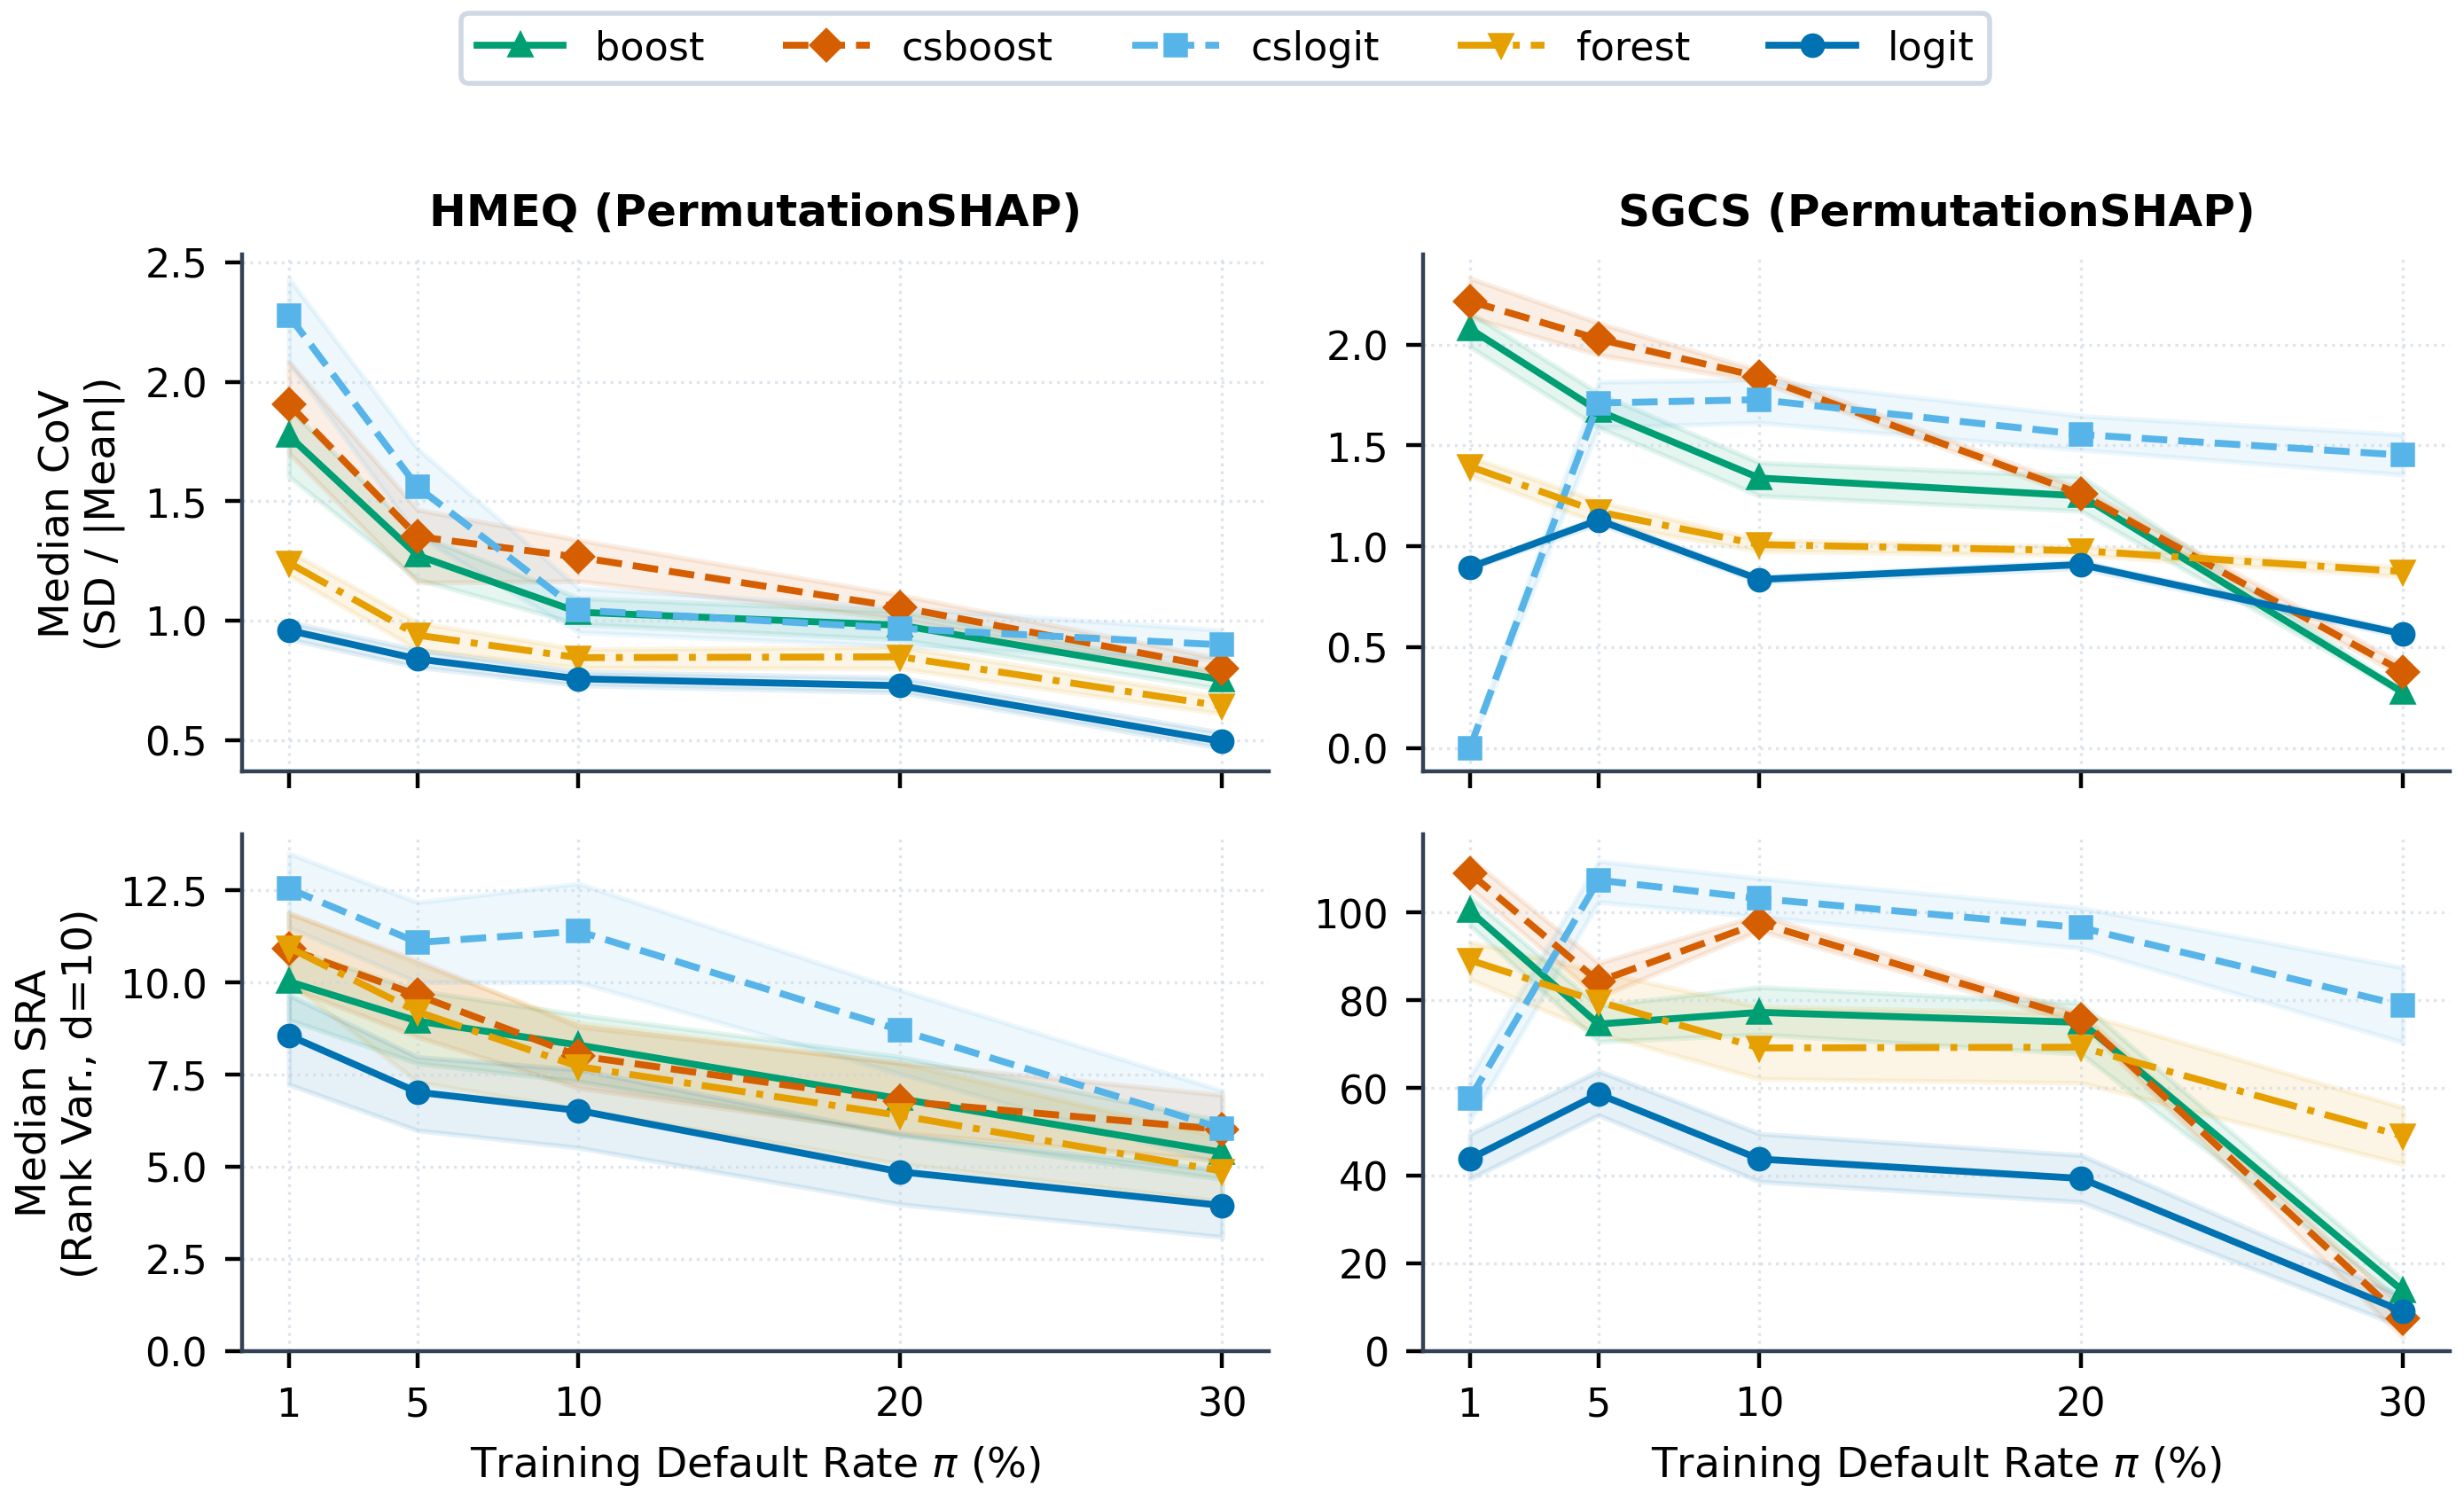

fig4_perturbation_vs_floor.png


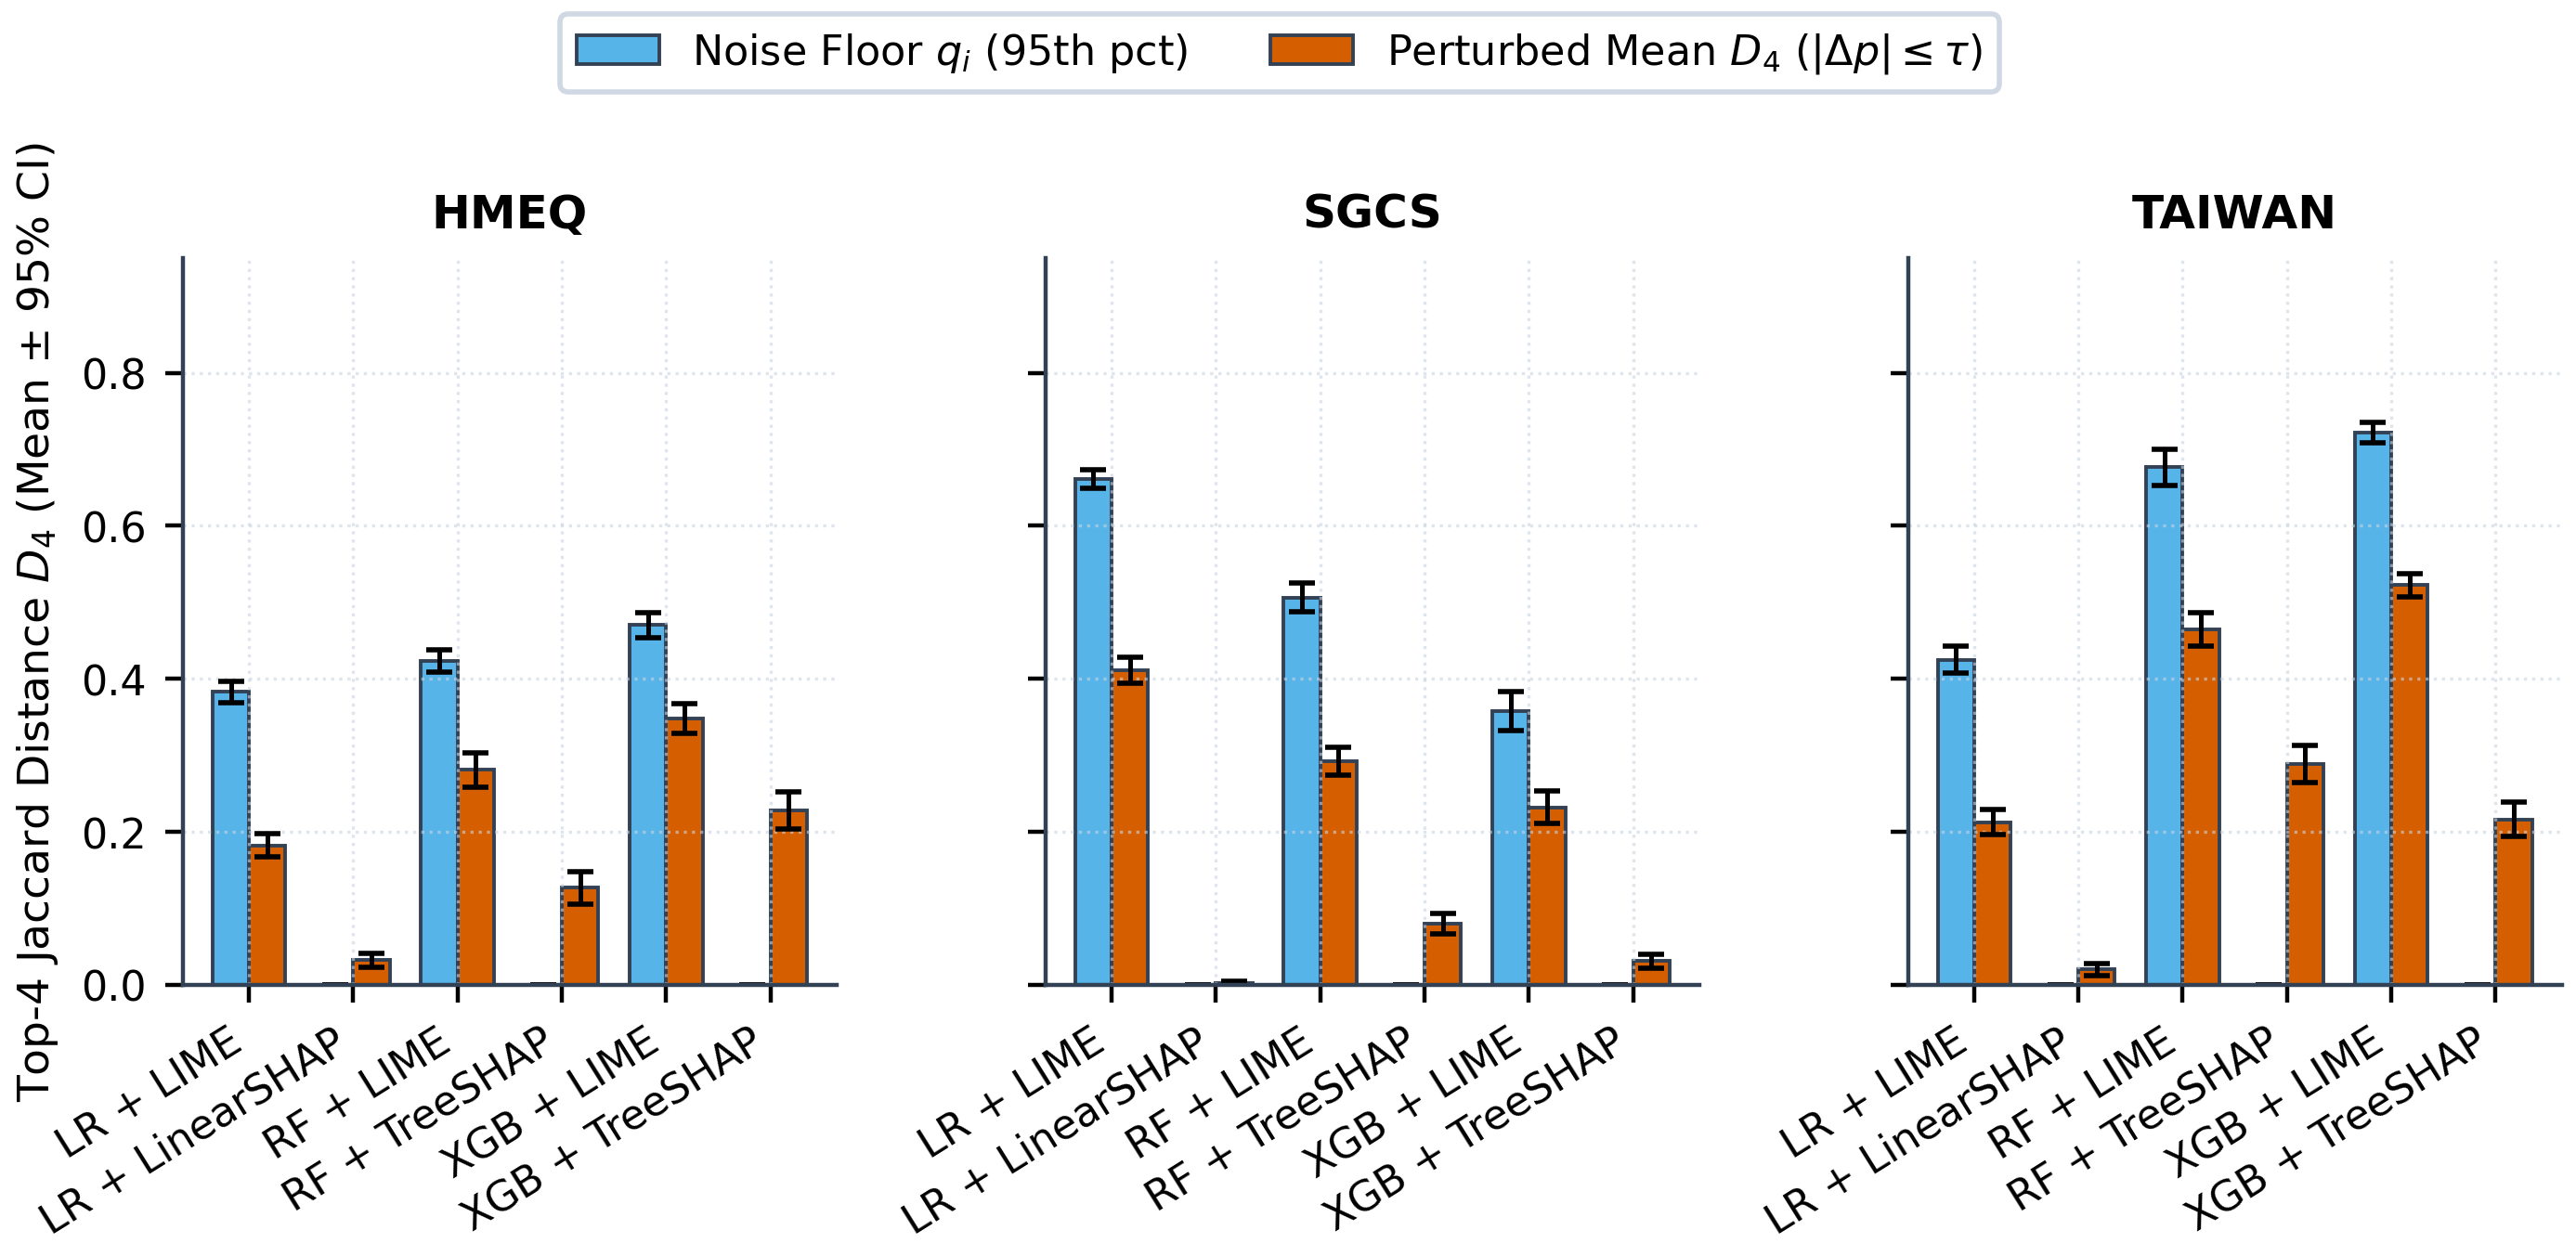

fig5_roc_comparison.png


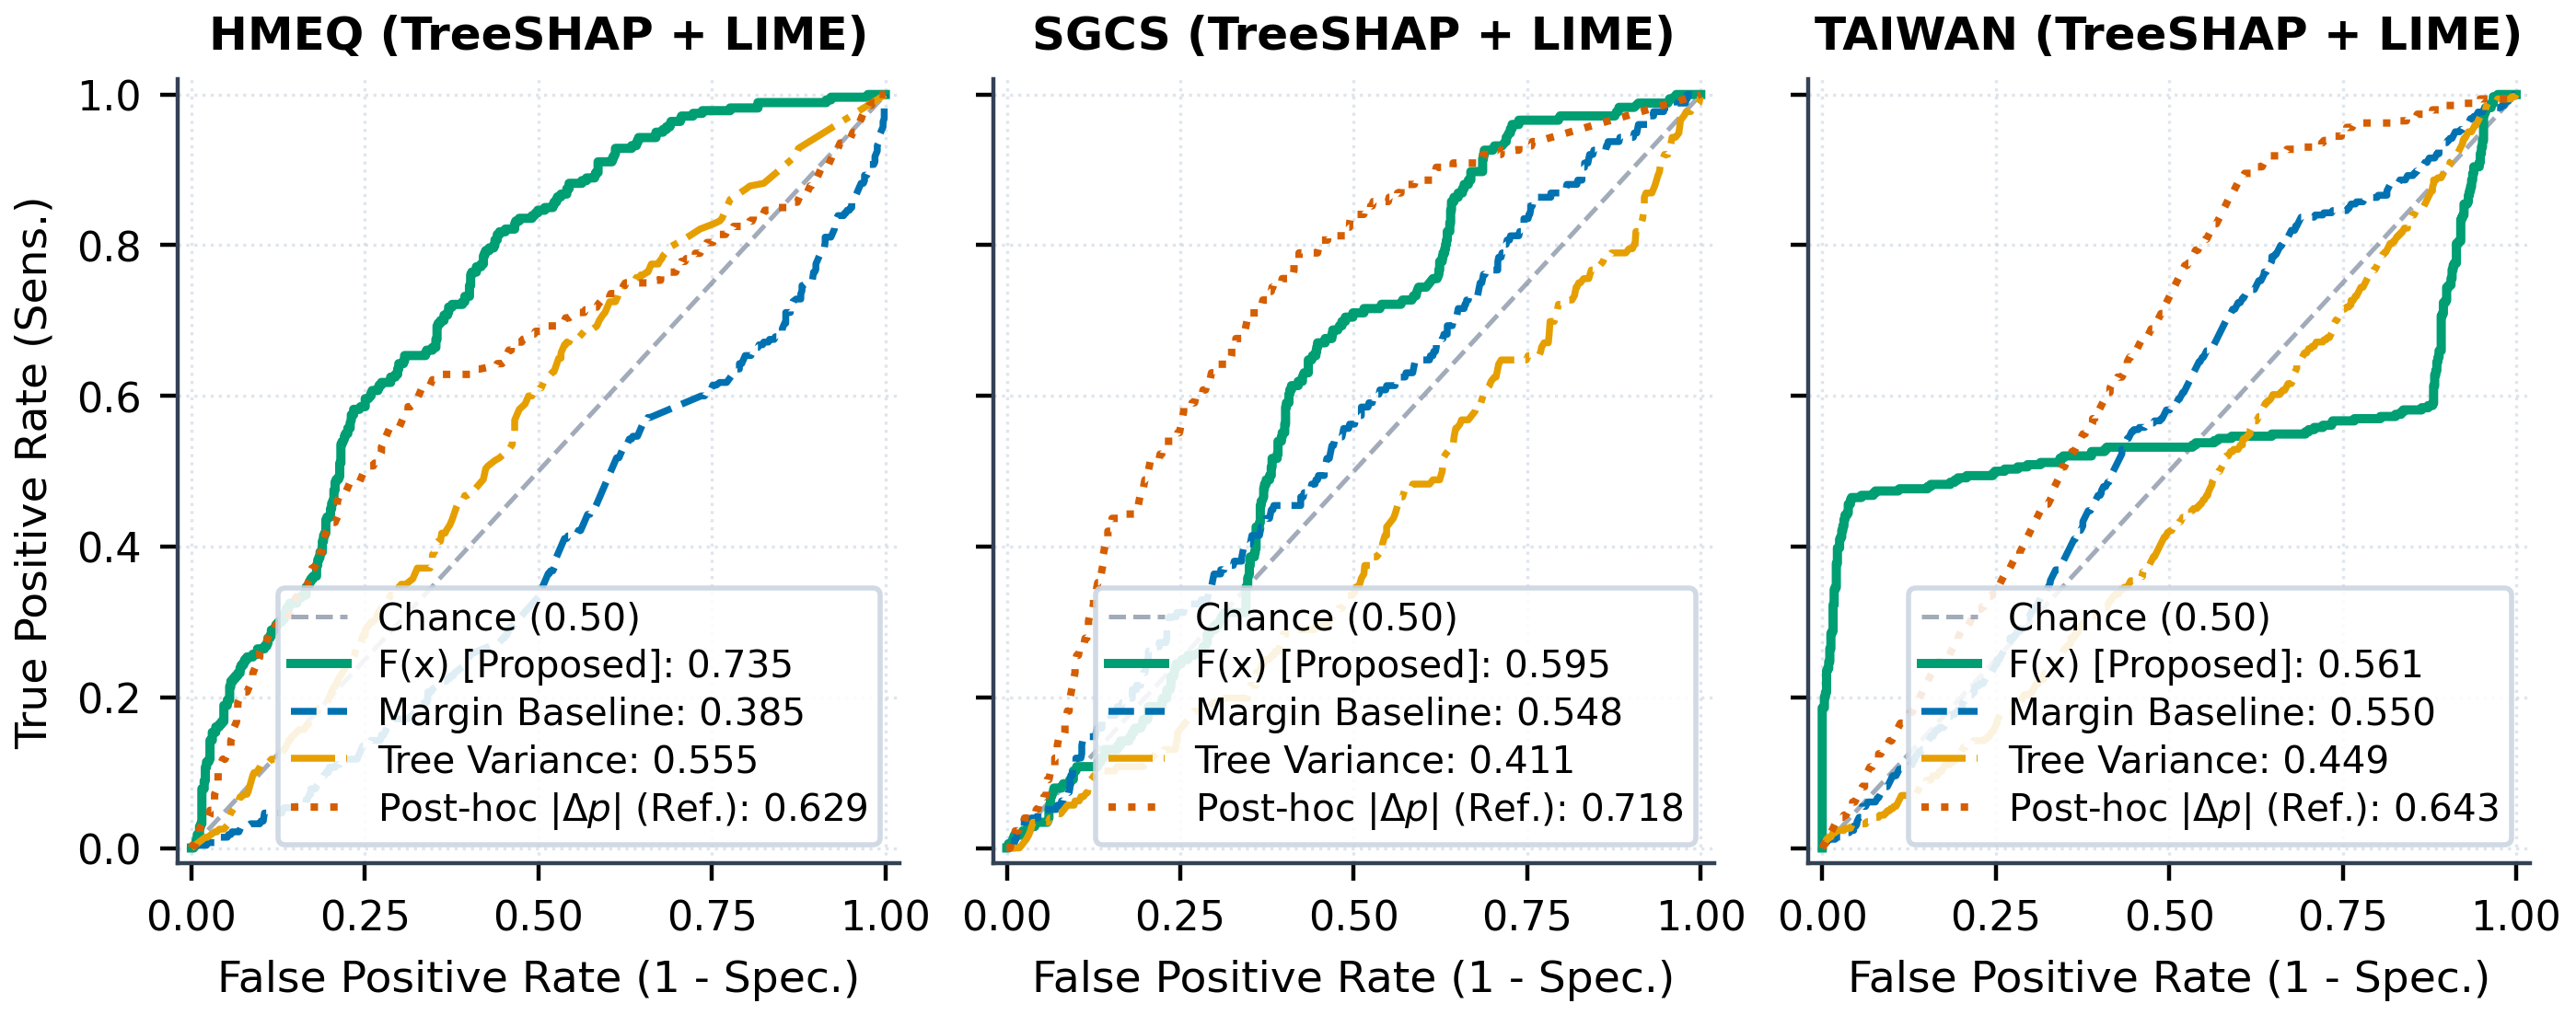

fig6_double_dissociation.png


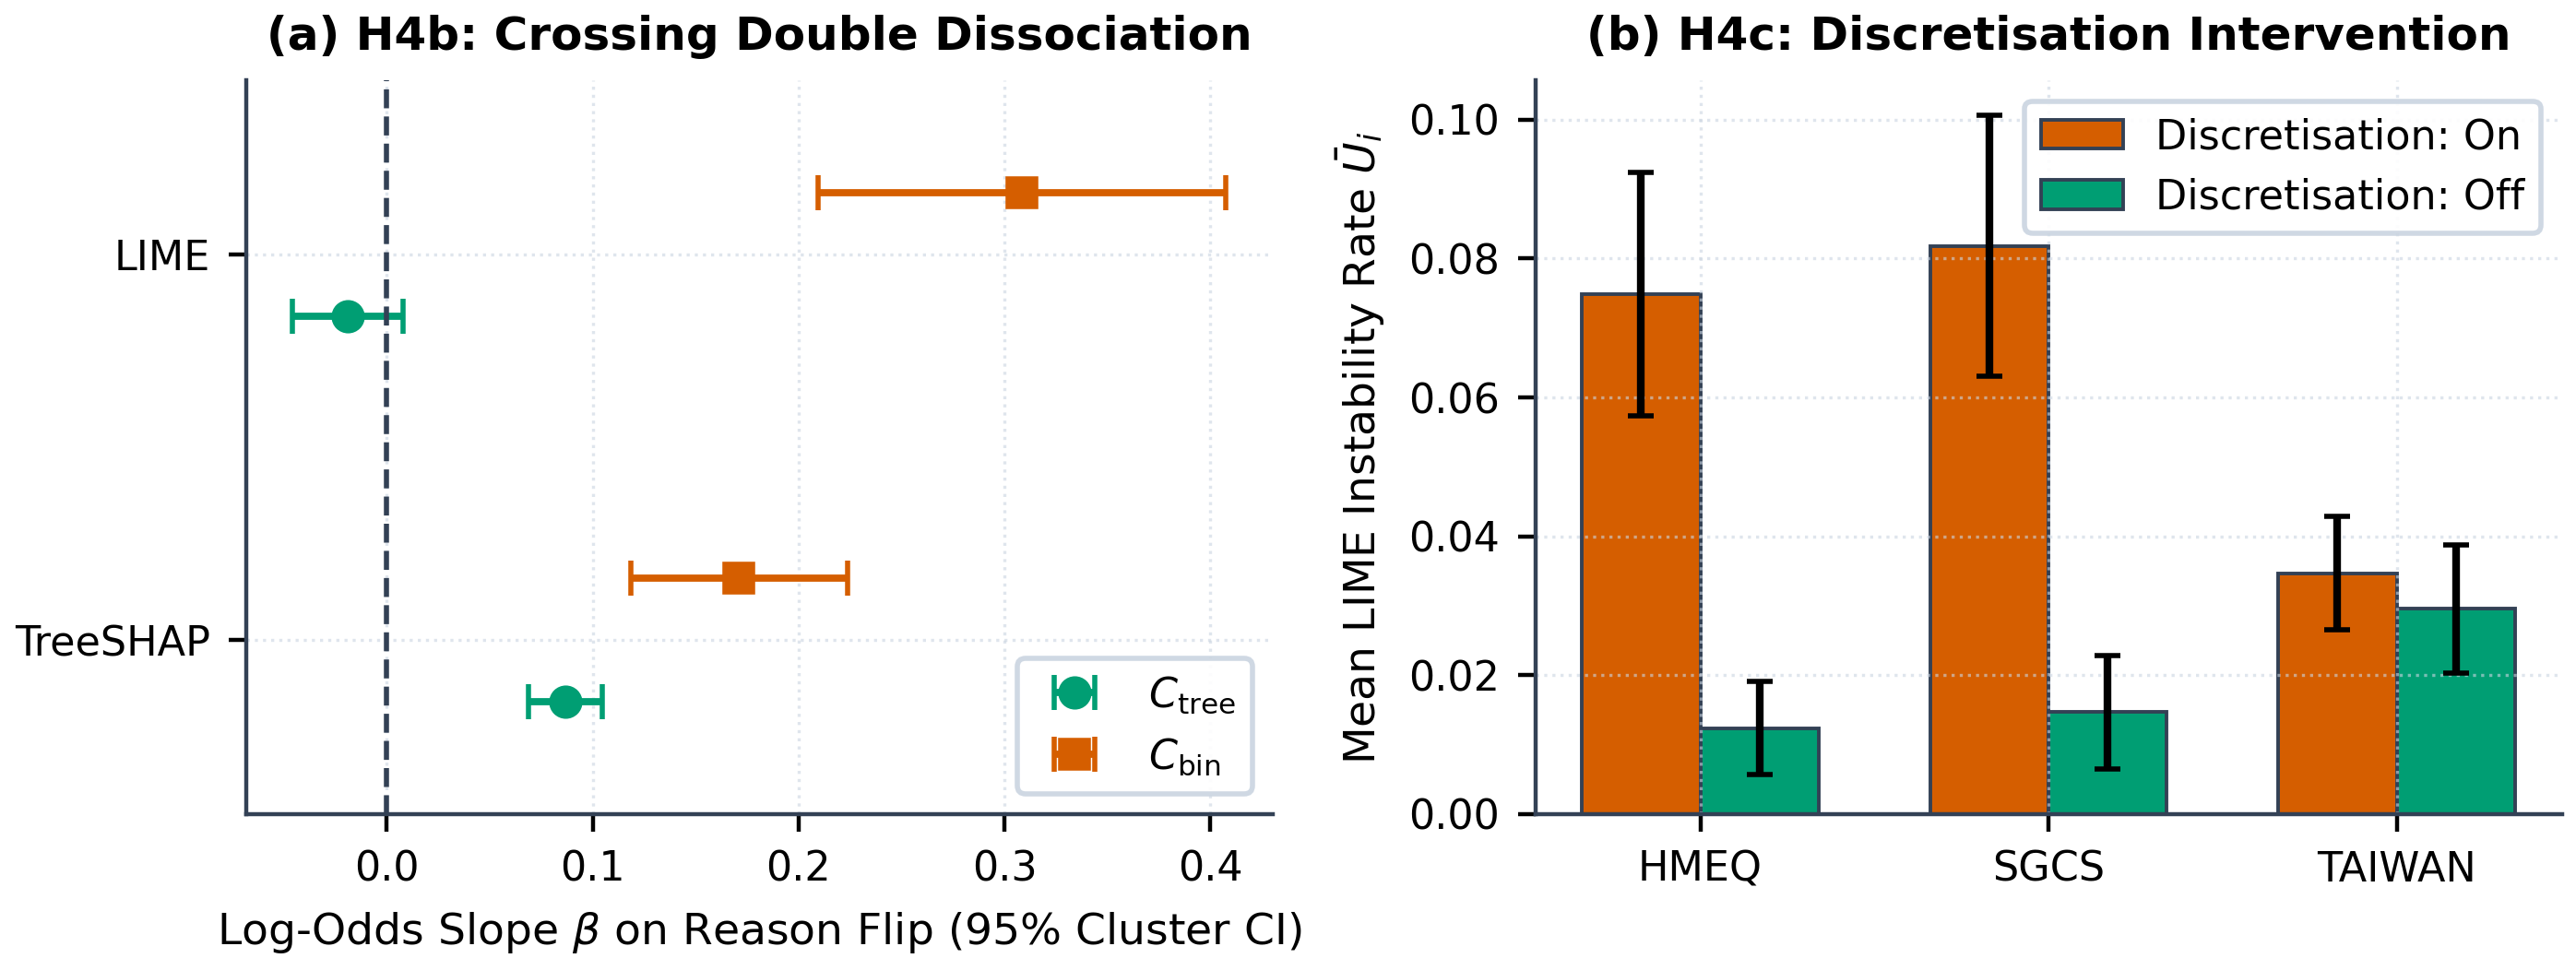

fig7_robustness_ablation.png


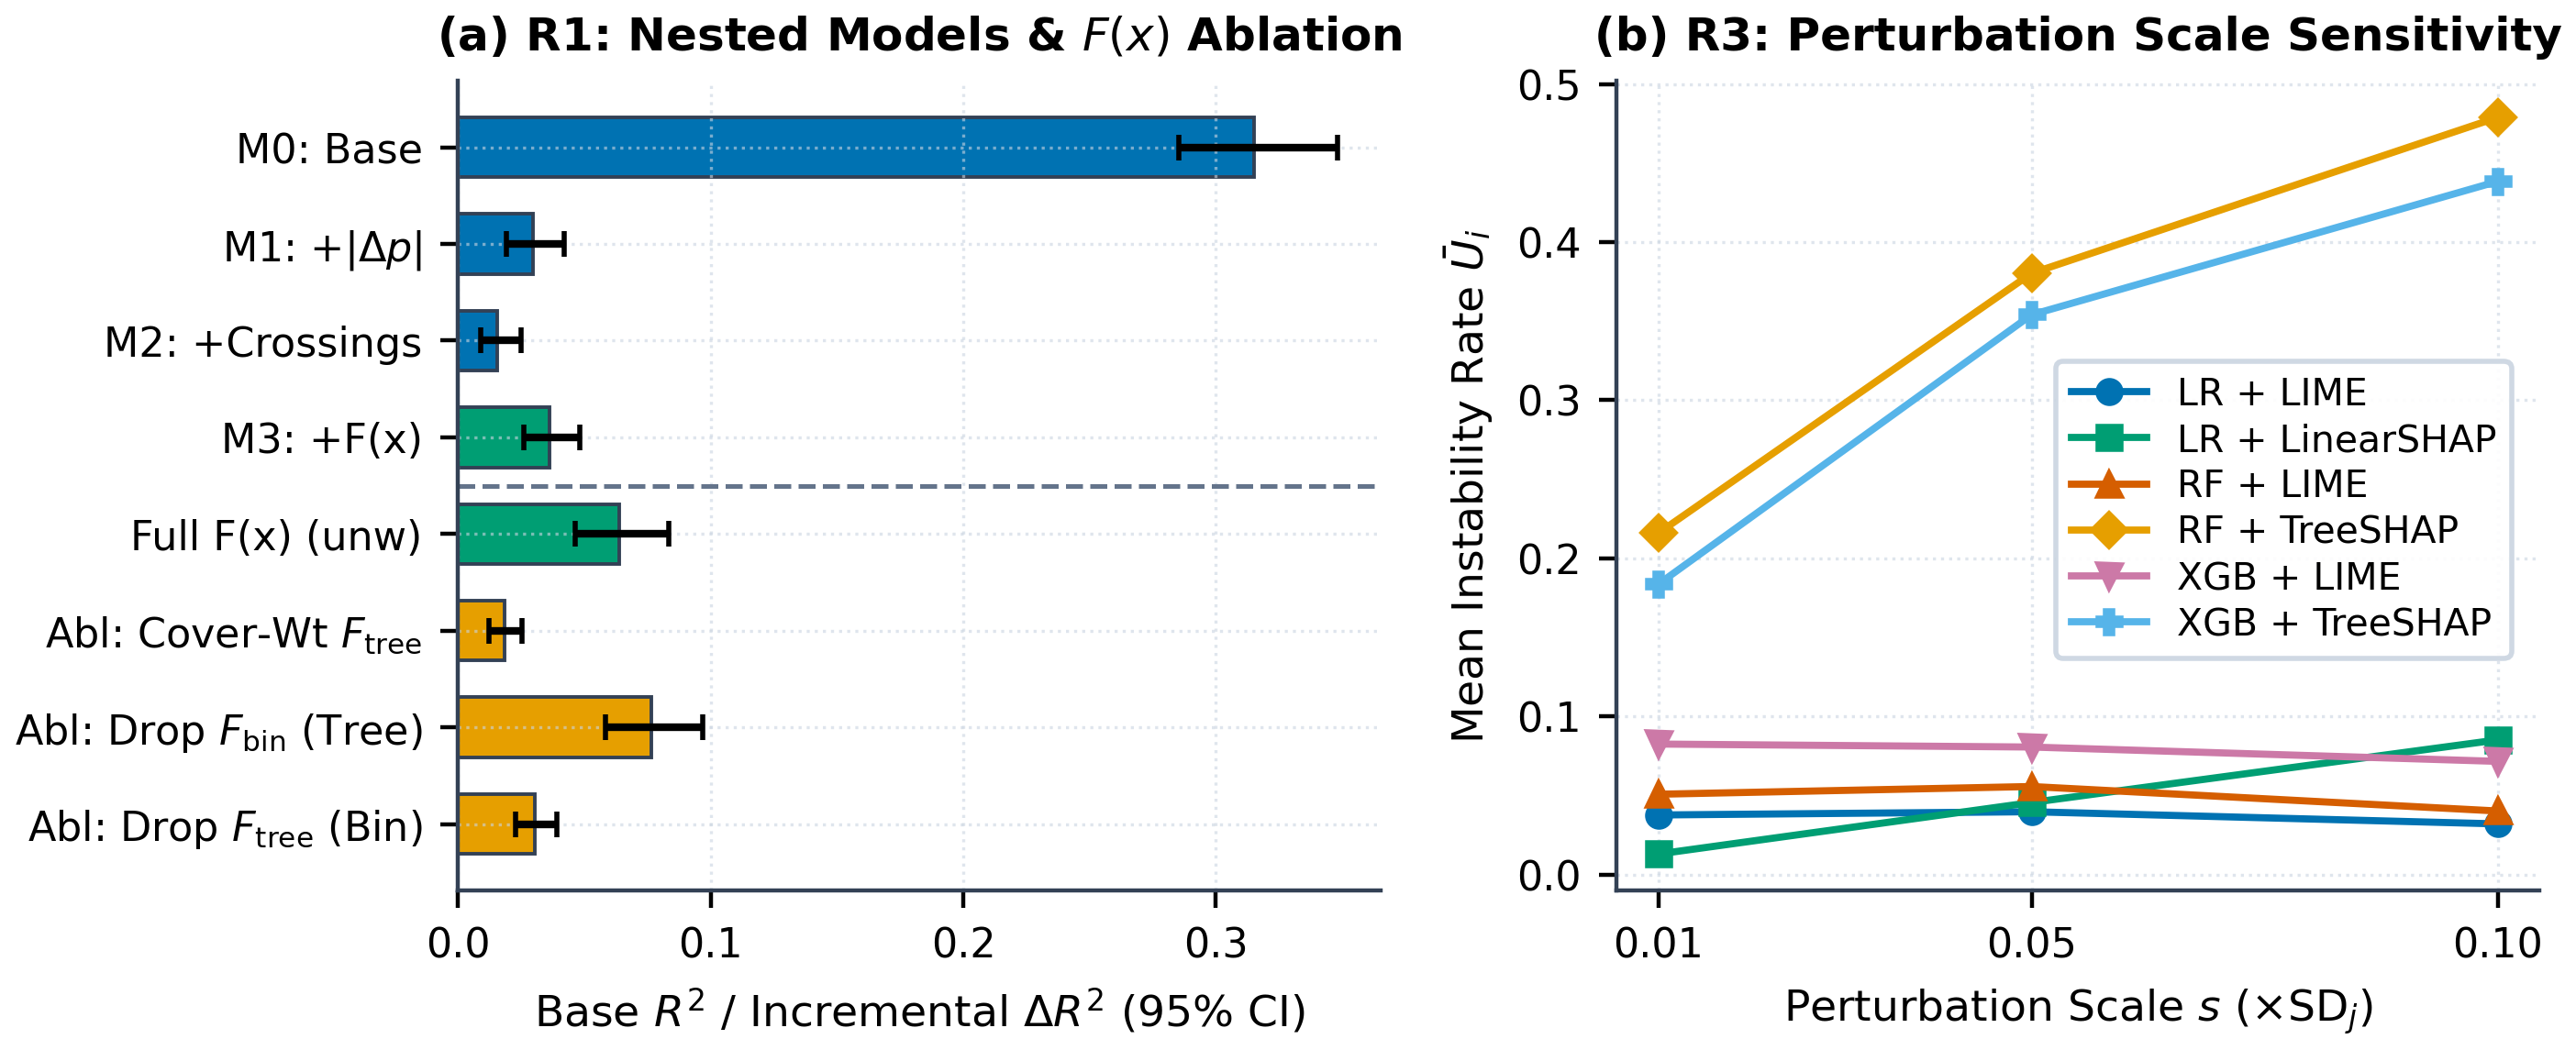

In [7]:
with open(results_dir / "case_study_hmeq.json", "r", encoding="utf-8") as fh:
    case_study = json.load(fh)
print(json.dumps(case_study, indent=2))

for fig_file in sorted(figures_dir.glob("*.png")):
    print(fig_file.name)
    display(Image(filename=str(fig_file), width=750))
